# 03 · Segmentation instead of boxes

Drawing boxes on every flower head is too much work. What if we skip the
labelling and use models that **already know how to segment**? Segmentation
gives pixel masks instead of boxes, and there are two flavours:

* **Semantic**: every pixel gets a class ("flower", "plant", "vase"...). It
  says *where* flowers are, but touching flower heads merge into one blob.
* **Instance**: one mask per object, so two overlapping flower heads stay two
  masks. This is what we would need to count and classify individual flowers.

We try both on **the same one second of video as notebook 02** (107.0-108.0 s,
30 frames at 30 fps, the pink bouquet filling the view) and compare with the
earlier detectors. Nothing here is trained by us; the point is what
*pretrained* segmentation gives us with **zero annotation**.

| Method | Kind | Trained on | Needs |
|---|---|---|---|
| YOLO26s-seg | instance | COCO (80 classes, **no flower**) | nothing: a negative control |
| YOLO26s-sem (ADE20K) | semantic | ADE20K (150 classes, **has "flower"**) | nothing |
| SegFormer-B2 (ADE20K) | semantic | ADE20K | nothing |
| YOLOE-26s-seg | instance | open vocabulary | a text prompt, example boxes, or nothing |
| SAM 2.1 tiny | instance | "segment anything" | nothing; slow; masks have no names |
| SAM 3 | instance | concept prompts | a text prompt; **gated** (needs Hugging Face access), see section 5 |

**Setup.** `pip install -r requirements-notebook.txt`, then install Ultralytics
*without* its dependencies (its normal install pulls a second OpenCV build):
`pip install ultralytics --no-deps polars ultralytics-thop psutil pyyaml
requests`. Ultralytics is AGPL-3.0; that is fine for this private analysis.
Its analytics are switched off and its weights are kept under `models/`.

Contents: 1 Negative control · 2 Semantic: which pixels are flower · 3 YOLOE
instances (text, prompt-free, visual prompt) · 4 SAM 2.1 segment-everything +
a flower filter · 5 SAM 3 · 6 Scoreboard · 7 Take-aways

In [1]:
import gc
import time
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from bouquet_checker import segmentation as sg
from bouquet_checker import video
from bouquet_checker.config import DATASET_DIR
from bouquet_checker.detection import Detection, draw_detections

# Inline figures as JPEG (quality 90) to keep the saved notebook small.
%config InlineBackend.figure_format = "jpeg"
%config InlineBackend.print_figure_kwargs = {"bbox_inches": "tight", "pil_kwargs": {"quality": 90}}

plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False,
                     "axes.spines.right": False})
pd.set_option("display.width", 170)

VIDEO_URL = "https://www.youtube.com/watch?v=QSVyyrKea14"
WINDOW_START, WINDOW_S = 107.0, 1.0           # the same second as notebook 02

path = video.download_video(VIDEO_URL, max_height=720)
info = video.video_info(path)
frames = list(video.sample_frames(path, every_s=1 / info.fps,
                                  start_s=WINDOW_START, end_s=WINDOW_START + WINDOW_S))
STRIP = list(range(0, len(frames), 3))        # every 3rd frame, 10 in total


def t_of(k):
    return frames[k].time_s - frames[0].time_s


timings = {}                                  # seconds per frame, per method
print(f"{len(frames)} frames, {frames[0].time_s:.3f}-{frames[-1].time_s:.3f} s, {info.width}x{info.height}")


def show_strip(images, titles, cols=5, title=None, size=(640, 360)):
    rows = int(np.ceil(len(images) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(3.5 * cols, 2.2 * rows + 0.5), squeeze=False)
    for ax in axes.ravel():
        ax.axis("off")
    for ax, image, t in zip(axes.ravel(), images, titles):
        ax.imshow(image.resize(size))
        ax.set_title(t, fontsize=8, pad=2)
    if title:
        fig.suptitle(title, fontsize=11)
    plt.tight_layout()
    plt.show()

30 frames, 107.000-107.967 s, 1280x720


## 1 · Negative control: YOLO26 segmentation trained on COCO

The pretrained YOLO26 *instance* models know the 80 COCO classes. COCO has
"potted plant" and "vase" but **no "flower"**, so we expect this to be blind to
flower heads. It is a useful control: it shows what "just run YOLO26-seg" gives.

classes found in the 30 frames (score >= 0.10): {'potted plant': 35, 'chair': 32, 'bowl': 46, 'dining table': 6, 'cake': 1, 'vase': 21, 'knife': 3}
'flower' among them: False | seconds per frame: 0.19


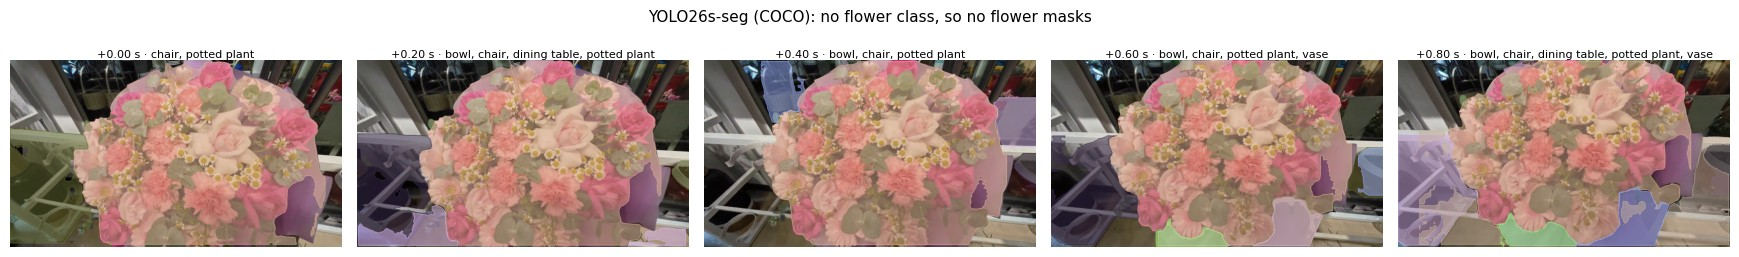

In [2]:
coco = sg.YoloSegmenter("yolo26s-seg.pt")
t0 = time.perf_counter()
coco_out = [coco.segment(f.image, conf=0.10) for f in frames]
timings["YOLO26s-seg (COCO)"] = (time.perf_counter() - t0) / len(frames)
del coco
gc.collect()

seen = Counter(i.label for out in coco_out for i in out)
print("classes found in the 30 frames (score >= 0.10):", dict(seen))
print("'flower' among them:", "flower" in seen, "| seconds per frame:", round(timings["YOLO26s-seg (COCO)"], 2))

picks = STRIP[::2]
show_strip([sg.overlay_instances(frames[k].image, coco_out[k]) for k in picks],
           [f"+{t_of(k):.2f} s · " + ", ".join(sorted({i.label for i in coco_out[k]})) if coco_out[k] else f"+{t_of(k):.2f} s · nothing"
            for k in picks],
           title="YOLO26s-seg (COCO): no flower class, so no flower masks")

## 2 · Semantic: which pixels are flower?

Two independent semantic models trained on **ADE20K** (150 scene classes,
including "flower"): YOLO26s-sem and SegFormer-B2. If they agree, we can trust
"flower pixels" as a signal. We keep only the flower mask of each frame.

In [3]:
flower_masks, other_classes, sem_names = {}, {}, {}
for name, loader in (("YOLO26s-sem (ADE20K)", sg.YoloSemanticSegmenter),
                     ("SegFormer-B2 (ADE20K)", sg.SegformerSemanticSegmenter)):
    model = loader()
    t0 = time.perf_counter()
    outputs = [model.segment(f.image) for f in frames]
    timings[name] = (time.perf_counter() - t0) / len(frames)
    names = outputs[0][1]
    ids = sg.find_class_ids(names, "flower")
    flower_masks[name] = np.stack([sg.class_mask(m, ids) for m, _ in outputs])
    counts = Counter()
    for class_map, _ in outputs:
        counts.update(dict(zip(*np.unique(class_map, return_counts=True))))
    other_classes[name] = {names[int(i)]: n / (len(frames) * class_map.size) for i, n in counts.items()}
    del model, outputs
    gc.collect()
    print(f"{name}: {timings[name]:.2f} s/frame, 'flower' = class id {ids}")

YOLO26s-sem (ADE20K): 0.93 s/frame, 'flower' = class id [66]


C:\Users\carl0\vsc\cat-project\.venv\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading weights:   0%|          | 0/380 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 380/380 [00:00<00:00, 23869.82it/s]

SegFormer-B2 (ADE20K): 2.09 s/frame, 'flower' = class id [66]


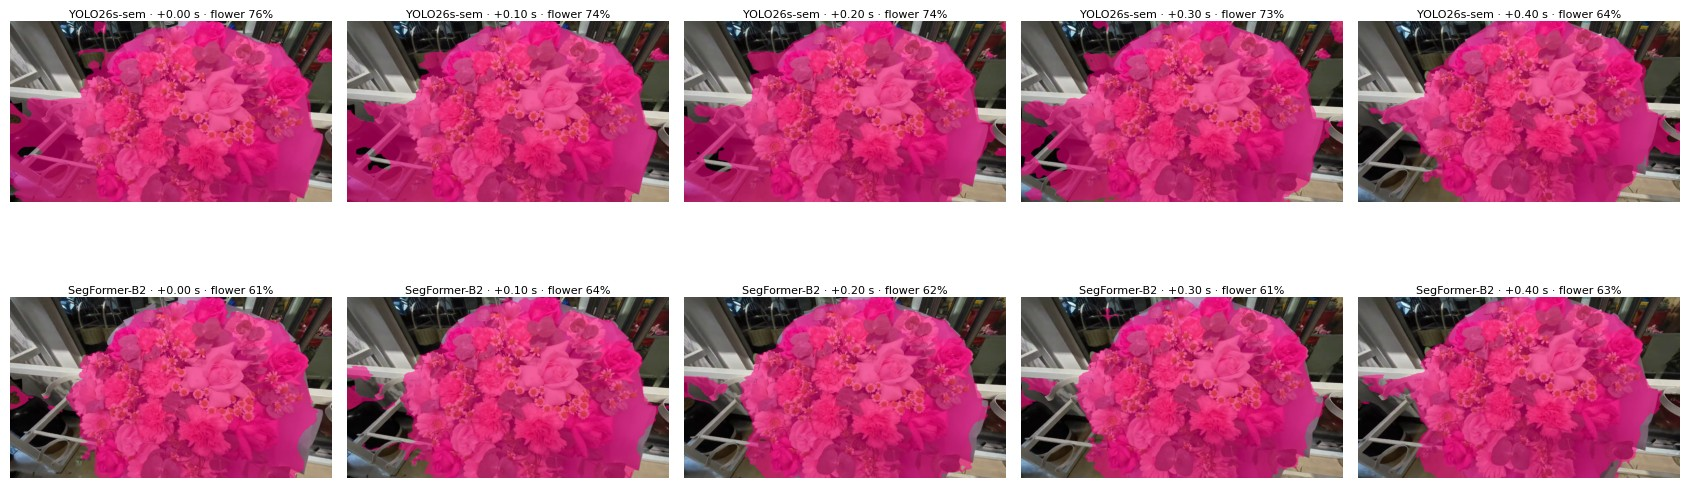

In [4]:
fig, axes = plt.subplots(2, 5, figsize=(17, 6.6))
for row, name in enumerate(flower_masks):
    for ax, k in zip(axes[row], STRIP):
        share = flower_masks[name][k].mean()
        ax.imshow(sg.overlay_mask(frames[k].image, flower_masks[name][k], (255, 0, 130), 0.55).resize((640, 360)))
        ax.set_title(f"{name.split(' ')[0]} · +{t_of(k):.2f} s · flower {share:.0%}", fontsize=8, pad=2)
        ax.axis("off")
plt.tight_layout()
plt.show()

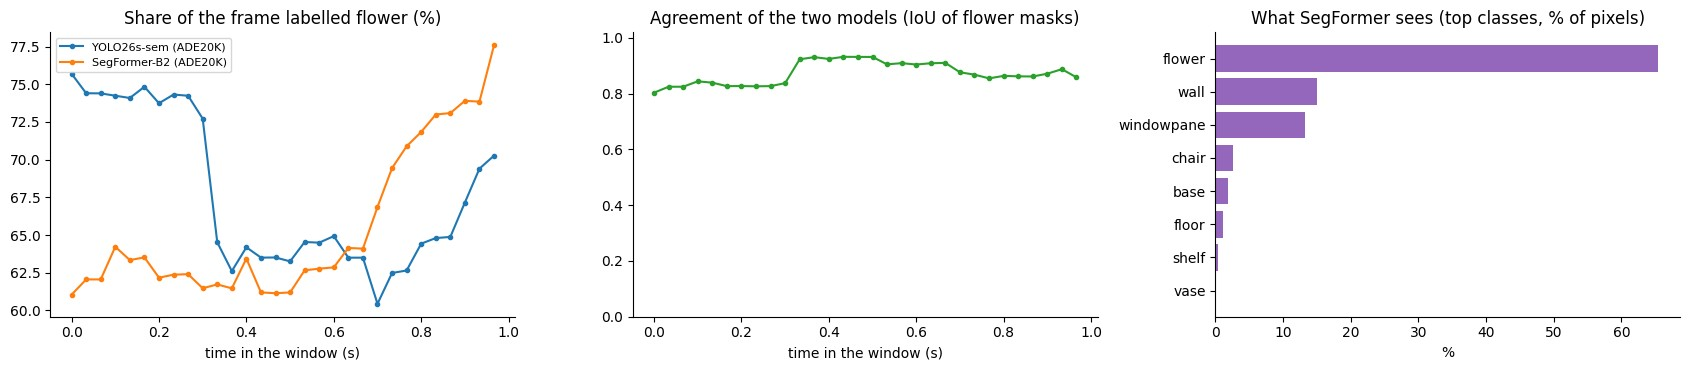

mean agreement: IoU 0.87  (min 0.80, max 0.93)


In [5]:
a, b = flower_masks.values()
share = {n: m.reshape(len(frames), -1).mean(axis=1) for n, m in flower_masks.items()}
iou = [sg.mask_iou(a[k], b[k]) for k in range(len(frames))]

fig, axes = plt.subplots(1, 3, figsize=(17, 3.8))
t_axis = [t_of(k) for k in range(len(frames))]
for name, values in share.items():
    axes[0].plot(t_axis, values * 100, marker="o", ms=3, label=name)
axes[0].set(title="Share of the frame labelled flower (%)", xlabel="time in the window (s)")
axes[0].legend(fontsize=8)
axes[1].plot(t_axis, iou, marker="o", ms=3, color="tab:green")
axes[1].set(title="Agreement of the two models (IoU of flower masks)", xlabel="time in the window (s)", ylim=(0, 1.02))
top = sorted(other_classes["SegFormer-B2 (ADE20K)"].items(), key=lambda kv: -kv[1])[:8]
axes[2].barh([n for n, _ in top][::-1], [100 * v for _, v in top][::-1], color="tab:purple")
axes[2].set(title="What SegFormer sees (top classes, % of pixels)", xlabel="%")
plt.tight_layout()
plt.show()
print(f"mean agreement: IoU {np.mean(iou):.2f}  (min {np.min(iou):.2f}, max {np.max(iou):.2f})")

Both models label roughly 60% of the frame as flower and agree closely. But
this is **semantic**: it cannot tell one flower head from the next, and the
wrapping paper and foliage inside a bouquet make the "flower" region a big blob
rather than a set of heads. It is a good *where are flowers* signal and a
useful ingredient (section 4), but not a flower counter.

## 3 · YOLOE: open-vocabulary instance segmentation

YOLOE ([Ultralytics YOLOE-26](https://docs.ultralytics.com/models/yoloe/)) is a
real-time instance segmenter that takes its classes **at run time**: a **text
prompt**, **example boxes** (a "visual prompt": no training) or **nothing**
(a built-in 4,585-word vocabulary). It is far faster than the earlier
open-vocabulary detectors (well under a second per frame on this CPU).

### 3a · Text prompts

The word matters. We sweep several prompts on every 3rd frame (score >= 0.10).

In [6]:
yoloe = sg.YoloSegmenter("yoloe-26s-seg.pt", prompts=["flower"])
SWEEP = {"flower": ["flower"], "flowers": ["flowers"], "flower head": ["flower head"],
         "bloom": ["bloom"], "bouquet": ["bouquet"], "rose": ["rose"],
         "carnation": ["carnation"], "rose+carnation+gerbera+daisy": ["rose", "carnation", "gerbera", "daisy"]}
rows = []
for label, prompts in SWEEP.items():
    yoloe.set_prompts(prompts)
    outs = [yoloe.segment(frames[k].image, conf=0.10) for k in STRIP]
    areas = [i.area / (info.width * info.height) for o in outs for i in o]
    rows.append({"prompt": label, "instances / frame": round(np.mean([len(o) for o in outs]), 1),
                 "best score": round(max((i.score for o in outs for i in o), default=0), 2),
                 "median mask (% of frame)": round(100 * float(np.median(areas)), 1) if areas else 0})
pd.DataFrame(rows).set_index("prompt")

C:\Users\carl0\vsc\cat-project\.venv\lib\site-packages\torch\jit\_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(


,instances / frame,best score,median mask (% of frame)
prompt,,,
flower,1.1,0.83,54.2
flowers,1.0,0.63,54.2
flower head,0.7,0.13,54.2
bloom,1.0,0.48,54.2
bouquet,1.0,0.63,54.6
rose,0.0,0.00,0.0
carnation,0.0,0.00,0.0
rose+carnation+gerbera+daisy,1.0,0.67,54.3


C:\Users\carl0\vsc\cat-project\.venv\lib\site-packages\torch\jit\_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(


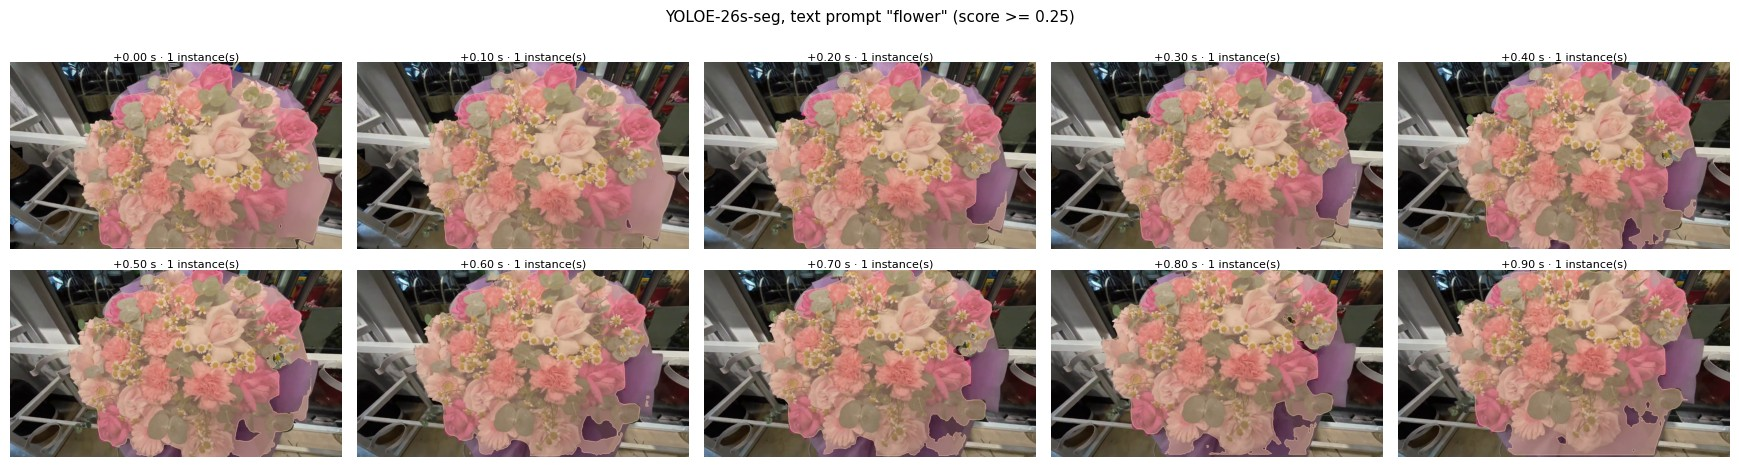

0.17 s/frame; mean instances/frame 1.0


30134

In [7]:
yoloe.set_prompts(["flower"])
t0 = time.perf_counter()
text_out = [yoloe.segment(f.image, conf=0.25) for f in frames]
TEXT_KEY = "YOLOE-26s text 'flower'"
timings[TEXT_KEY] = (time.perf_counter() - t0) / len(frames)
show_strip([sg.overlay_instances(frames[k].image, text_out[k]) for k in STRIP],
           [f"+{t_of(k):.2f} s · {len(text_out[k])} instance(s)" for k in STRIP],
           title='YOLOE-26s-seg, text prompt "flower" (score >= 0.25)')
print(f"{timings[TEXT_KEY]:.2f} s/frame; mean instances/frame {np.mean([len(o) for o in text_out]):.1f}")
del yoloe
gc.collect()

With the text "flower" YOLOE returns **one mask for the whole bouquet**, the
same "bunch, not head" behaviour as the box detectors, and species words
("rose", "carnation") find nothing.

### 3b · Prompt-free

The `-pf` model names whatever it sees from its built-in vocabulary.

labels found: {'flower': 30, 'basket': 8, 'chessboard': 1, 'tiramisu': 1, 'plate': 6, 'vase': 25, 'shopping basket': 1, 'assembly line': 17, 'bowl': 13, 'caldron': 5, 'car': 3, 'orangery': 1, 'restaurant patio': 1, 'loop': 2, 'conservatory': 2, 'workbench': 1}


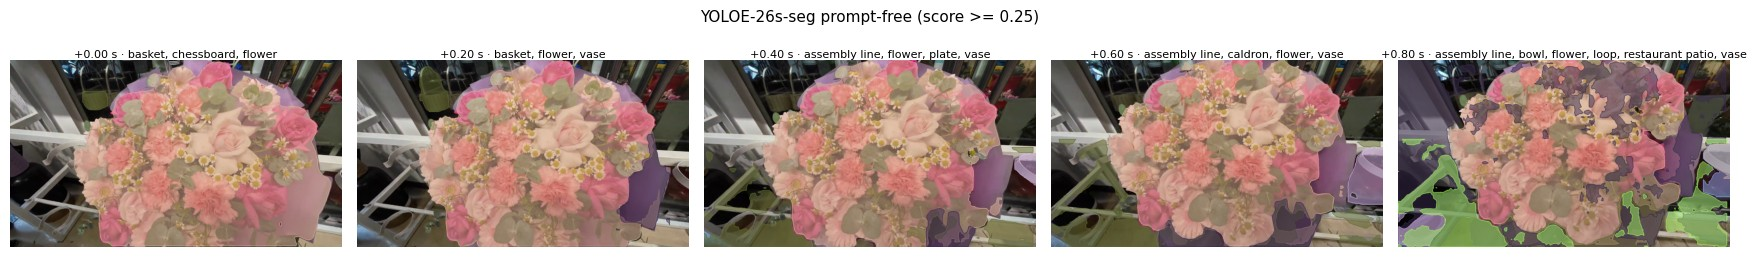

In [8]:
pf = sg.YoloSegmenter("yoloe-26s-seg-pf.pt")
t0 = time.perf_counter()
pf_out = [pf.segment(f.image, conf=0.25) for f in frames]
timings["YOLOE-26s prompt-free"] = (time.perf_counter() - t0) / len(frames)
del pf
gc.collect()
print("labels found:", dict(Counter(i.label for o in pf_out for i in o)))
show_strip([sg.overlay_instances(frames[k].image, pf_out[k]) for k in STRIP[::2]],
           [f"+{t_of(k):.2f} s · " + ", ".join(sorted({i.label for i in pf_out[k]})) for k in STRIP[::2]],
           title="YOLOE-26s-seg prompt-free (score >= 0.25)")

### 3c · Visual prompts: show it one flower head

This is the closest thing to "no annotation": instead of a dataset we draw
**three boxes** on a *different* moment of the video (102.0 s: a hot-pink rose,
a coral carnation, a large pale rose) and ask YOLOE for things that look like
them. Those three boxes are the entire labelling effort.

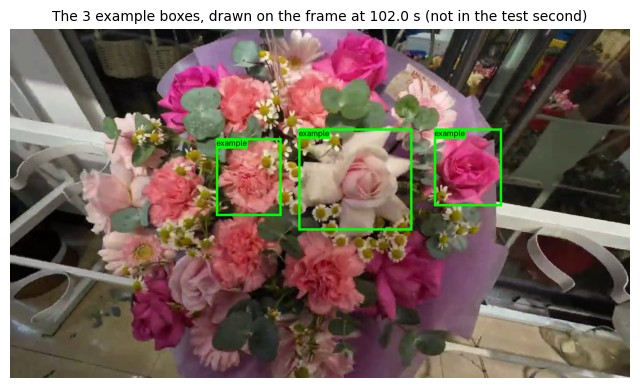

In [9]:
REF_TIME = 102.0
REF_BOXES = [[875, 205, 1015, 365], [425, 225, 560, 385], [595, 205, 830, 415]]
reference = video.read_frame(path, REF_TIME).image

fig, ax = plt.subplots(figsize=(8, 4.6))
ax.imshow(draw_detections(reference, [Detection(tuple(b), 1.0, "example") for b in REF_BOXES], width=5, show_score=False))
ax.set_title(f"The 3 example boxes, drawn on the frame at {REF_TIME} s (not in the test second)", fontsize=10)
ax.axis("off")
plt.show()

0.90 s/frame; instances/frame: mean 7.1, min 3, max 11; scores: median 0.04, max 0.14


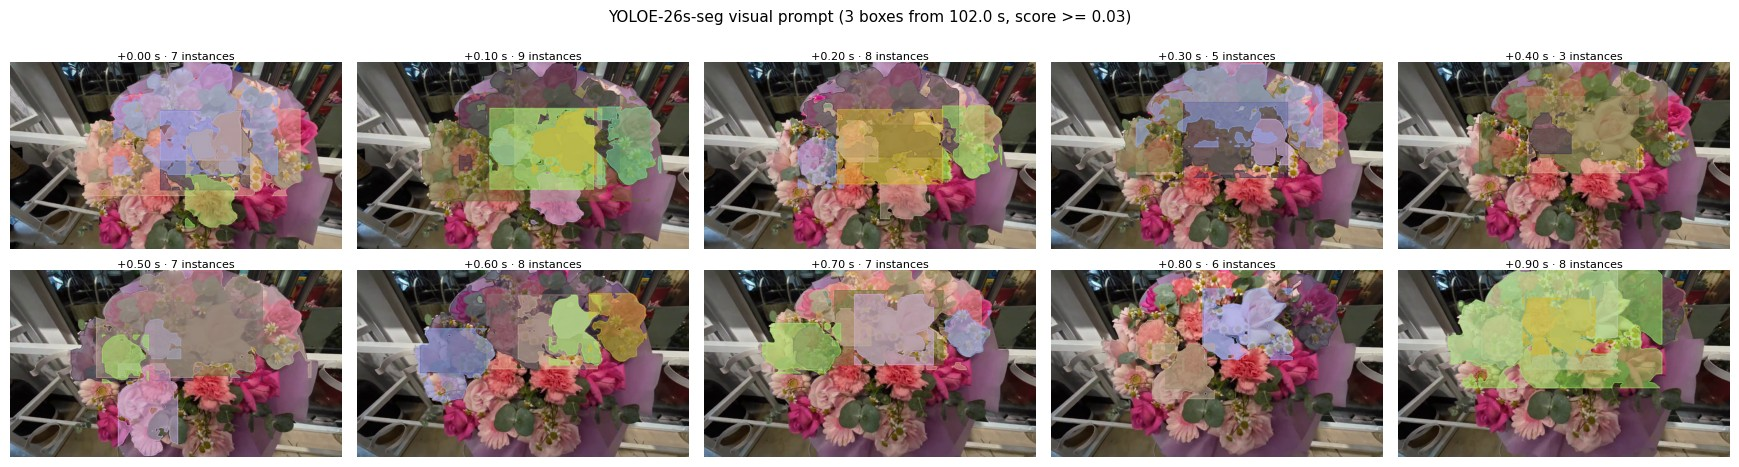

In [10]:
visual = sg.YoloeVisualSegmenter()
VIS_CONF = 0.03            # visual-prompt scores are tiny; 0.25 would return nothing
t0 = time.perf_counter()
vis_out = [visual.segment(f.image, reference, REF_BOXES, conf=VIS_CONF) for f in frames]
timings["YOLOE-26s visual prompt (3 boxes)"] = (time.perf_counter() - t0) / len(frames)
del visual
gc.collect()

scores = [i.score for o in vis_out for i in o]
print(f"{timings['YOLOE-26s visual prompt (3 boxes)']:.2f} s/frame; instances/frame: mean {np.mean([len(o) for o in vis_out]):.1f}, "
      f"min {min(len(o) for o in vis_out)}, max {max(len(o) for o in vis_out)}; "
      f"scores: median {np.median(scores):.2f}, max {max(scores):.2f}")
show_strip([sg.overlay_instances(frames[k].image, vis_out[k]) for k in STRIP],
           [f"+{t_of(k):.2f} s · {len(vis_out[k])} instances" for k in STRIP],
           title=f"YOLOE-26s-seg visual prompt (3 boxes from {REF_TIME} s, score >= {VIS_CONF})")

The visual prompt is the most interesting *idea* (a few examples instead of a
dataset), but here the scores are tiny (a fraction of the text-prompt scores)
and we had to drop the threshold to 0.03 to see anything, so treat the masks as
weak, uncalibrated candidates rather than detections.

## 4 · SAM 2.1 "segment everything", then keep what is flower

SAM 2.1 segments *any* object but has no idea what it is, and on CPU it takes
tens of seconds per frame, so we run it on **5 frames** (0.2 s apart). Then we
combine it with section 2: **keep only the SAM masks that lie mostly on
SegFormer's flower pixels** and have a plausible size for a flower head. Neither
part needs a label, but the pair might isolate individual flowers.

In [11]:
SAM_FRAMES = [0, 6, 12, 18, 24]
GRID = 16                                        # 16 x 16 = 256 prompt points
cache_file = DATASET_DIR / "cache" / f"sam2_tiny_{WINDOW_START:.1f}s_g{GRID}_{'-'.join(map(str, SAM_FRAMES))}.npz"

if cache_file.exists():
    cached = np.load(cache_file)
    counts, scores_all, masks_all = cached["counts"], cached["scores"], cached["masks"]
    sam_seconds = float(cached["seconds_per_frame"])
    sam_out, start = [], 0
    for n in counts:
        sam_out.append([sg.Instance(masks_all[start + j], float(scores_all[start + j]), "object") for j in range(n)])
        start += n
    print(f"loaded {int(counts.sum())} masks from cache ({cache_file.name})")
else:
    sam = sg.Sam2AutoMasker()
    t0 = time.perf_counter()
    sam_out = [sam.segment(frames[k].image, points_per_crop=GRID) for k in SAM_FRAMES]
    sam_seconds = (time.perf_counter() - t0) / len(SAM_FRAMES)
    del sam
    gc.collect()
    cache_file.parent.mkdir(parents=True, exist_ok=True)
    np.savez_compressed(
        cache_file, counts=np.array([len(o) for o in sam_out]),
        scores=np.array([i.score for o in sam_out for i in o]),
        masks=np.stack([i.mask for o in sam_out for i in o]), seconds_per_frame=sam_seconds)
timings["SAM 2.1 tiny (16x16 grid)"] = sam_seconds
print(f"SAM 2.1 tiny: {sam_seconds:.0f} s/frame; masks per frame: {[len(o) for o in sam_out]}")

loaded 182 masks from cache (sam2_tiny_107.0s_g16_0-6-12-18-24.npz)
SAM 2.1 tiny: 44 s/frame; masks per frame: [39, 35, 44, 33, 31]


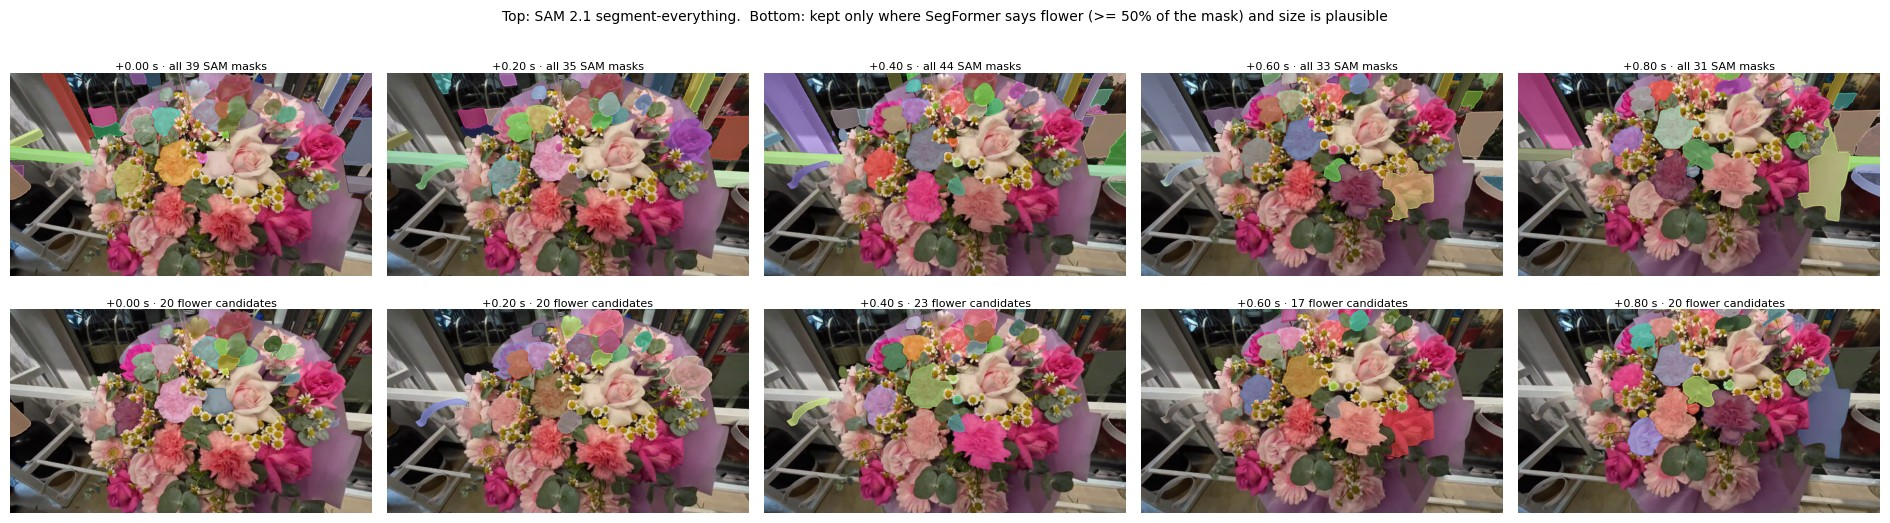

In [12]:
SEG_NAME = "SegFormer-B2 (ADE20K)"
candidates = [sg.keep_by_semantic(sam_out[i], flower_masks[SEG_NAME][k], min_fraction=0.5,
                                  min_area_frac=0.0005, max_area_frac=0.25)
              for i, k in enumerate(SAM_FRAMES)]

fig, axes = plt.subplots(2, len(SAM_FRAMES), figsize=(3.8 * len(SAM_FRAMES), 5.6))
for i, k in enumerate(SAM_FRAMES):
    axes[0][i].imshow(sg.overlay_instances(frames[k].image, sam_out[i]).resize((640, 360)))
    axes[0][i].set_title(f"+{t_of(k):.2f} s · all {len(sam_out[i])} SAM masks", fontsize=8, pad=2)
    axes[1][i].imshow(sg.overlay_instances(frames[k].image, candidates[i]).resize((640, 360)))
    axes[1][i].set_title(f"+{t_of(k):.2f} s · {len(candidates[i])} flower candidates", fontsize=8, pad=2)
for ax in axes.ravel():
    ax.axis("off")
fig.suptitle("Top: SAM 2.1 segment-everything.  Bottom: kept only where SegFormer says flower (>= 50% of the mask) and size is plausible", fontsize=10)
plt.tight_layout()
plt.show()

In [13]:
# Do the candidates persist from one sampled frame to the next (0.2 s apart)?
persist = [np.nan] + [len(sg.match_instances(p, c, 0.5)) / len(p) if p else np.nan
                      for p, c in zip(candidates, candidates[1:])]
area_pct = [np.median([100 * i.area / frames[0].image.width / frames[0].image.height for i in c]) if c else 0 for c in candidates]
pd.DataFrame({"SAM masks": [len(o) for o in sam_out], "flower candidates": [len(c) for c in candidates],
              "median candidate size (% frame)": np.round(area_pct, 2),
              "kept from previous sampled frame (IoU>=0.5)": np.round(persist, 2)},
             index=[f"+{t_of(k):.2f} s" for k in SAM_FRAMES])

,SAM masks,flower candidates,median candidate size (% frame),kept from previous sampled frame (IoU>=0.5)
+0.00 s,39,20,0.41,NaN
+0.20 s,35,20,0.51,0.35
+0.40 s,44,23,0.34,0.00
+0.60 s,33,17,0.41,0.00
+0.80 s,31,20,0.55,0.06


## 5 · SAM 3 (the latest SAM): give it a word, get every instance

SAM 3 does in one step what the other methods could not: given the text
**"flower"** it returns a mask for **every** matching object, with a score.
It is **gated** on Hugging Face (manual approval, about 3.4 GB, needs a token;
if you do not have access this section prints how to get it and everything
after it is skipped). It runs on this CPU at roughly 40 s per frame *per
prompt*.

What we run, kept small because it is slow:

* **"flower"** on 10 frames 0.1 s apart (so masks can be matched between
  frames to measure stability),
* **"leaf"** on 5 frames (to remove "flower" masks that are really leaves),
* **"rose"** and **"carnation"** on one frame (can it name species?).

Everything is stored at half resolution and cached in `data/raw/cache/`, so a
re-run only pays for it once. Masks are kept down to score 0.30; the displayed
threshold is 0.5 (SAM 3's default).

In [14]:
SAM3_FRAMES = STRIP                     # 10 frames, 0.1 s apart
SAM3_LEAF_FRAMES = SAM_FRAMES           # 5 frames, 0.2 s apart
SPECIES_FRAME, SPECIES_PROMPTS = SAM_FRAMES[1], ["rose", "carnation"]
SAM3_LOW, SAM3_THR = 0.30, 0.50


def half(image):
    return image.resize((image.width // 2, image.height // 2))


def save_sam3(file, results, seconds):
    arrays = {"seconds": np.array(seconds)}
    for (prompt, k), found in results.items():
        arrays[f"{prompt}__{k}__scores"] = np.array([i.score for i in found], dtype=np.float32)
        arrays[f"{prompt}__{k}__masks"] = (np.stack([i.mask for i in found]) if found
                                           else np.zeros((0, 1, 1), dtype=bool))
    file.parent.mkdir(parents=True, exist_ok=True)
    np.savez_compressed(file, **arrays)


def load_sam3(file):
    data, results = np.load(file), {}
    for key in data.files:
        if key.endswith("__scores"):
            prompt, k, _ = key.split("__")
            masks = data[key.replace("scores", "masks")]
            results[(prompt, int(k))] = [sg.Instance(m, float(s), prompt)
                                         for m, s in zip(masks, data[key])]
    return results, float(data["seconds"])


sam3_cache = DATASET_DIR / "cache" / f"sam3_{WINDOW_START:.1f}s_half.npz"
sam3_res, sam3_seconds = {}, float("nan")

if sam3_cache.exists():
    sam3_res, sam3_seconds = load_sam3(sam3_cache)
    print(f"loaded {len(sam3_res)} SAM 3 results from cache ({sam3_cache.name})")
else:
    try:
        sam3 = sg.Sam3TextSegmenter()
    except sg.Sam3AccessError as err:
        sam3 = None
        print("SAM 3 skipped:", err)
    if sam3 is not None:
        jobs = ([("flower", k) for k in SAM3_FRAMES] + [("leaf", k) for k in SAM3_LEAF_FRAMES]
                + [(p, SPECIES_FRAME) for p in SPECIES_PROMPTS])
        t0 = time.perf_counter()
        for n, (prompt, k) in enumerate(jobs, 1):
            found = sam3.segment(frames[k].image, prompt, threshold=SAM3_LOW)
            sam3_res[(prompt, k)] = [sg.Instance(i.mask[::2, ::2], i.score, i.label) for i in found]
            print(f"  {n}/{len(jobs)} {prompt!r} at +{t_of(k):.2f} s: {len(found)} masks (score >= {SAM3_LOW}), "
                  f"{time.perf_counter() - t0:.0f} s elapsed", flush=True)
        sam3_seconds = (time.perf_counter() - t0) / len(jobs)
        del sam3
        gc.collect()
        save_sam3(sam3_cache, sam3_res, sam3_seconds)

HAVE_SAM3 = bool(sam3_res)
if HAVE_SAM3:
    timings["SAM 3 (per prompt and frame)"] = sam3_seconds
    print(f"SAM 3: {sam3_seconds:.0f} s per prompt and frame")


def keep(prompt, k, thr=SAM3_THR):
    return [i for i in sam3_res[(prompt, k)] if i.score >= thr]

[transformers] `memory_attention_rope_theta` is deprecated and will be removed in v5.0. Use `rope_parameters['rope_theta']` instead.


Loading weights:   0%|          | 0/1468 [00:00<?, ?it/s]

Loading weights:   8%|▊         | 123/1468 [00:00<00:03, 345.04it/s]

Loading weights:  11%|█         | 158/1468 [00:00<00:04, 270.73it/s]

Loading weights:  12%|█▏        | 183/1468 [00:00<00:08, 153.13it/s]

...

  14/17 'leaf' at +0.60 s: 68 masks (score >= 0.3), 609 s elapsed


  15/17 'leaf' at +0.80 s: 63 masks (score >= 0.3), 651 s elapsed


  16/17 'rose' at +0.20 s: 24 masks (score >= 0.3), 693 s elapsed


  17/17 'carnation' at +0.20 s: 17 masks (score >= 0.3), 734 s elapsed


SAM 3: 43 s per prompt and frame


### 5a · "flower" on 10 frames

Masks with score >= 0.5. The table shows how the count depends on the score
threshold (SAM 3 gives a score per mask, so the threshold is a real dial).

              mean instances / frame
score >= 0.3                    69.8
score >= 0.4                    57.3
score >= 0.5                    45.0
score >= 0.7                    25.3

mask size at score >= 0.5: median 0.17% of the frame, largest 4.4% (a flower head is roughly 1-4%)


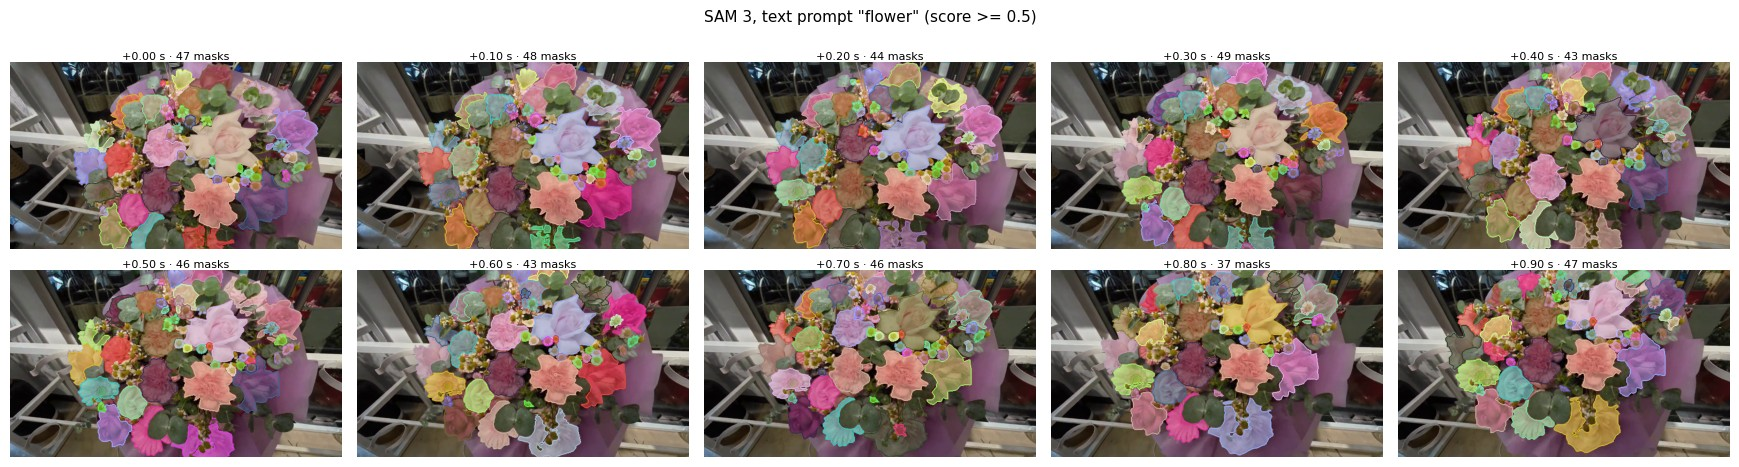

In [15]:
if HAVE_SAM3:
    rows = {f"score >= {thr}": [np.mean([sum(i.score >= thr for i in sam3_res[("flower", k)]) for k in SAM3_FRAMES])]
            for thr in (0.3, 0.4, 0.5, 0.7)}
    print(pd.DataFrame(rows, index=["mean instances / frame"]).T.round(1).to_string())
    areas = [100 * i.area / (frames[0].image.width // 2 * frames[0].image.height // 2)
             for k in SAM3_FRAMES for i in keep("flower", k)]
    print(f"\nmask size at score >= {SAM3_THR}: median {np.median(areas):.2f}% of the frame, "
          f"largest {max(areas):.1f}% (a flower head is roughly 1-4%)")
    show_strip([sg.overlay_instances(half(frames[k].image), keep("flower", k)) for k in SAM3_FRAMES],
               [f"+{t_of(k):.2f} s · {len(keep('flower', k))} masks" for k in SAM3_FRAMES],
               title=f'SAM 3, text prompt "flower" (score >= {SAM3_THR})')

### 5b · Removing leaves

Some "flower" masks are eucalyptus leaves. Because SAM 3 also understands
**"leaf"**, we can drop every "flower" mask that is mostly covered by "leaf"
masks (>= 50% of its pixels).

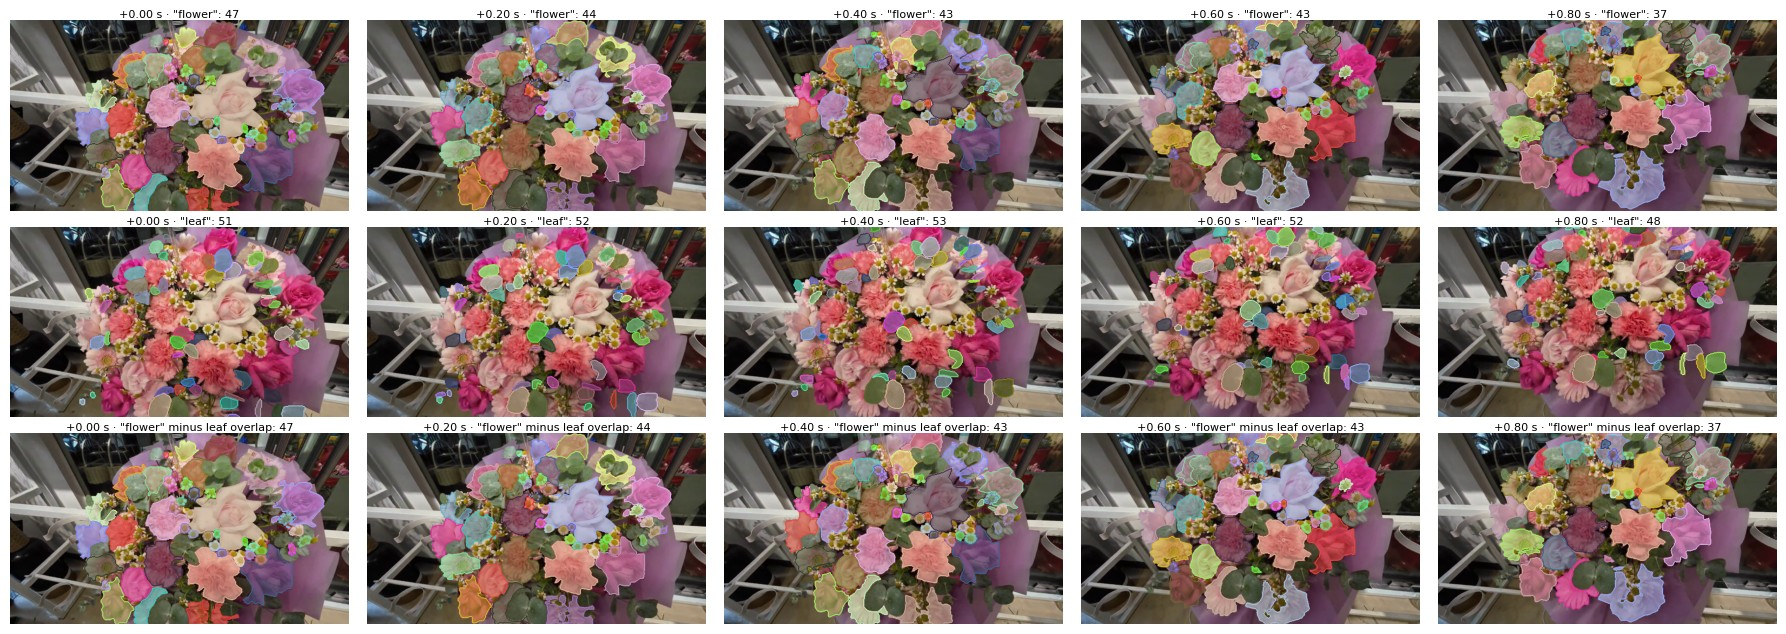

         flower  leaf  flower minus leaves
+0.00 s      47    51                   47
+0.20 s      44    52                   44
+0.40 s      43    53                   43
+0.60 s      43    52                   43
+0.80 s      37    48                   37


In [16]:
if HAVE_SAM3:
    cleaned = {k: sg.remove_overlapping(keep("flower", k), keep("leaf", k), 0.5) for k in SAM3_LEAF_FRAMES}
    fig, axes = plt.subplots(3, len(SAM3_LEAF_FRAMES), figsize=(3.6 * len(SAM3_LEAF_FRAMES), 6.4))
    for c, k in enumerate(SAM3_LEAF_FRAMES):
        for r, (label, found) in enumerate((('"flower"', keep("flower", k)), ('"leaf"', keep("leaf", k)),
                                            ('"flower" minus leaf overlap', cleaned[k]))):
            axes[r][c].imshow(sg.overlay_instances(half(frames[k].image), found).resize((640, 360)))
            axes[r][c].set_title(f"+{t_of(k):.2f} s · {label}: {len(found)}", fontsize=8, pad=2)
            axes[r][c].axis("off")
    plt.tight_layout()
    plt.show()
    print(pd.DataFrame({"flower": [len(keep("flower", k)) for k in SAM3_LEAF_FRAMES],
                        "leaf": [len(keep("leaf", k)) for k in SAM3_LEAF_FRAMES],
                        "flower minus leaves": [len(cleaned[k]) for k in SAM3_LEAF_FRAMES]},
                       index=[f"+{t_of(k):.2f} s" for k in SAM3_LEAF_FRAMES]).to_string())

### 5c · Are the masks stable from frame to frame?

Frames 0.1 s apart. **Persistence** is the share of the previous frame's masks
that can be found again (mask IoU >= 0.5). The camera is moving, so this is a
lower bound on stability: it is the work a tracker would have to do.

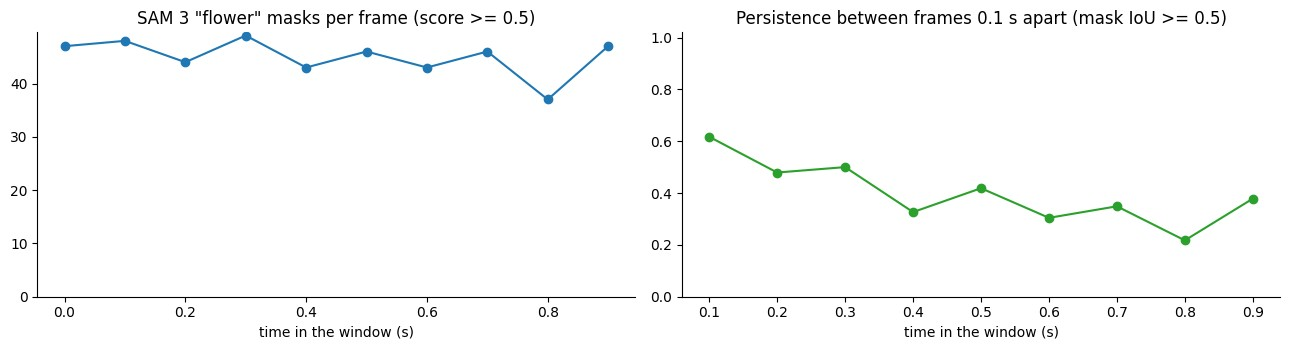

masks per frame: 37-49; mean persistence over 0.1 s: 0.40


In [17]:
if HAVE_SAM3:
    per_frame = [keep("flower", k) for k in SAM3_FRAMES]
    persistence = [np.nan] + [len(sg.match_instances(p, c, 0.5)) / len(p) if p else np.nan
                              for p, c in zip(per_frame, per_frame[1:])]
    fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
    t_axis = [t_of(k) for k in SAM3_FRAMES]
    axes[0].plot(t_axis, [len(p) for p in per_frame], marker="o")
    axes[0].set(title=f'SAM 3 "flower" masks per frame (score >= {SAM3_THR})', xlabel="time in the window (s)", ylim=(0, None))
    axes[1].plot(t_axis, persistence, marker="o", color="tab:green")
    axes[1].set(title="Persistence between frames 0.1 s apart (mask IoU >= 0.5)", xlabel="time in the window (s)", ylim=(0, 1.02))
    plt.tight_layout()
    plt.show()
    print(f"masks per frame: {min(map(len, per_frame))}-{max(map(len, per_frame))}; "
          f"mean persistence over 0.1 s: {np.nanmean(persistence):.2f}")

### 5d · Can it name the species?

The same word-prompt idea, with species instead of "flower". Because SAM 3
answers to *concepts*, this would be a shortcut to species labels. One frame,
score >= 0.5.

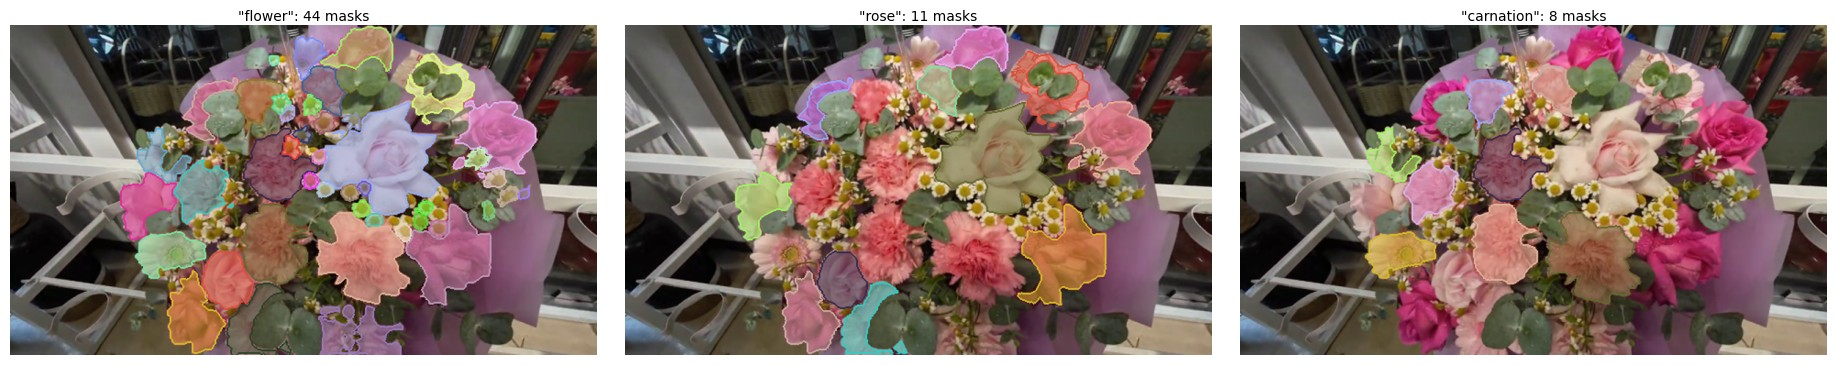

In [18]:
if HAVE_SAM3:
    k = SPECIES_FRAME
    panels = [("flower", keep("flower", k))] + [(p, keep(p, k)) for p in SPECIES_PROMPTS]
    fig, axes = plt.subplots(1, len(panels), figsize=(6.2 * len(panels), 3.6))
    for ax, (label, found) in zip(axes, panels):
        ax.imshow(sg.overlay_instances(half(frames[k].image), found).resize((800, 450)))
        ax.set_title(f'"{label}": {len(found)} masks', fontsize=10, pad=3)
        ax.axis("off")
    plt.tight_layout()
    plt.show()

## 6 · Scoreboard

One frame (+0.20 s), six ways to segment it, then everything in one table.

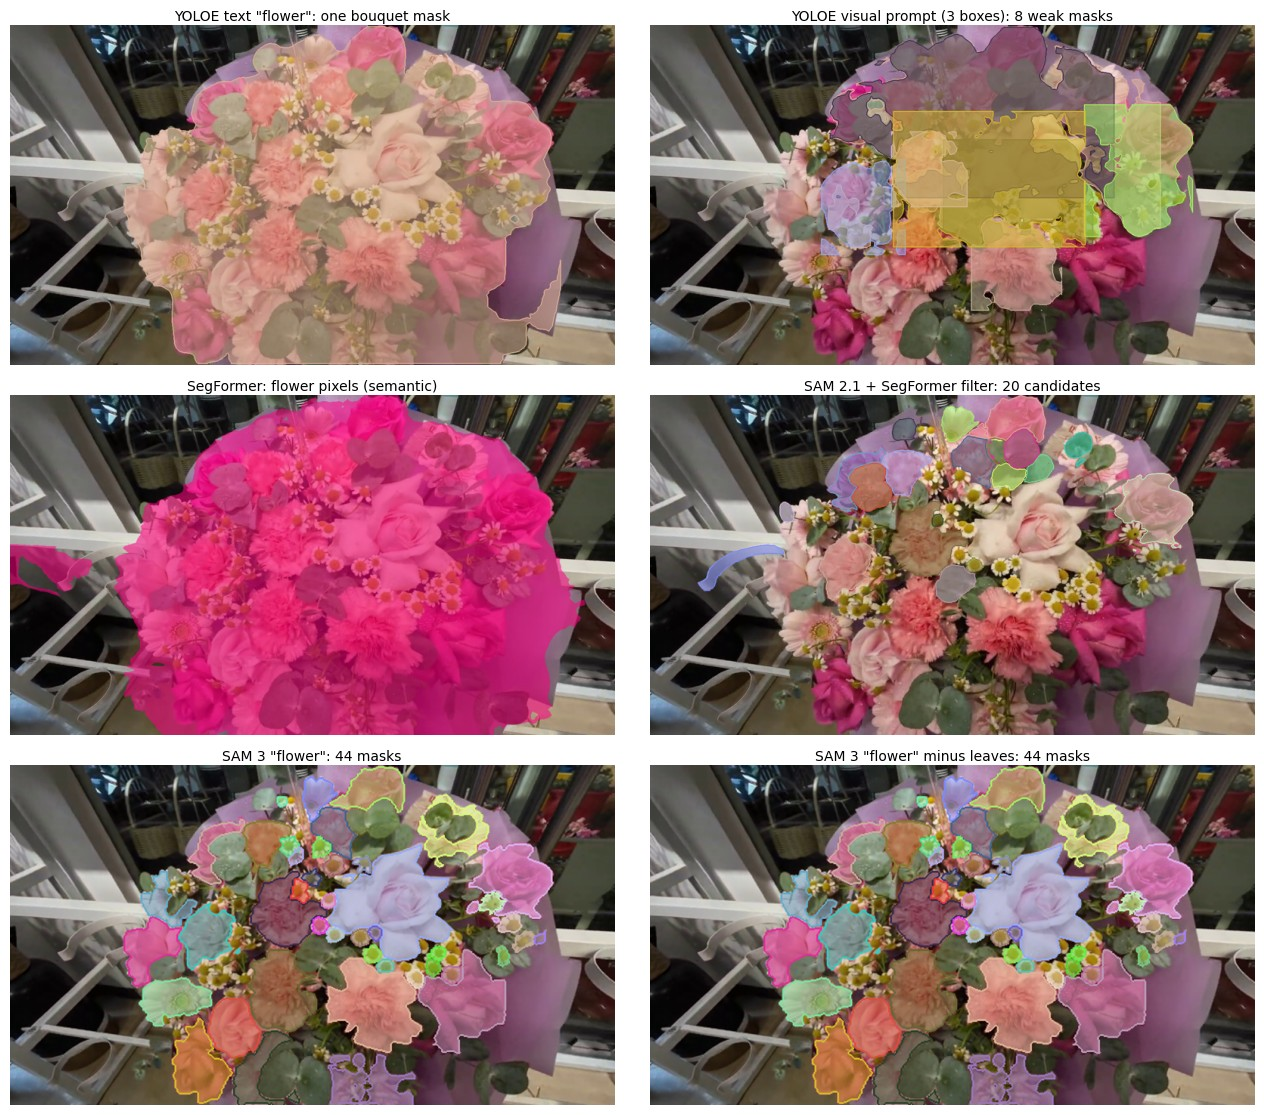

In [19]:
k, i = SAM_FRAMES[1], 1
panels = [
    (sg.overlay_instances(frames[k].image, text_out[k]), 'YOLOE text "flower": one bouquet mask'),
    (sg.overlay_instances(frames[k].image, vis_out[k]), f"YOLOE visual prompt (3 boxes): {len(vis_out[k])} weak masks"),
    (sg.overlay_mask(frames[k].image, flower_masks[SEG_NAME][k], (255, 0, 130), 0.55), "SegFormer: flower pixels (semantic)"),
    (sg.overlay_instances(frames[k].image, candidates[i]), f"SAM 2.1 + SegFormer filter: {len(candidates[i])} candidates"),
]
if HAVE_SAM3:
    panels += [
        (sg.overlay_instances(half(frames[k].image), keep("flower", k)), f'SAM 3 "flower": {len(keep("flower", k))} masks'),
        (sg.overlay_instances(half(frames[k].image), cleaned[k]), f'SAM 3 "flower" minus leaves: {len(cleaned[k])} masks'),
    ]
rows_n = int(np.ceil(len(panels) / 2))
fig, axes = plt.subplots(rows_n, 2, figsize=(13, 3.75 * rows_n))
for ax in axes.ravel():
    ax.axis("off")
for ax, (image, title) in zip(axes.ravel(), panels):
    ax.imshow(image.resize((800, 450)))
    ax.set_title(title, fontsize=10, pad=3)
plt.tight_layout()
plt.show()

In [20]:
rows = [
    {"method": "YOLO26s-seg (COCO)", "labels needed": "none",
     "s / frame": timings["YOLO26s-seg (COCO)"], "what it returns": f"{np.mean([len(o) for o in coco_out]):.1f} objects/frame, never a flower"},
    {"method": "YOLO26s-sem (ADE20K)", "labels needed": "none",
     "s / frame": timings["YOLO26s-sem (ADE20K)"], "what it returns": f"flower pixels ({share['YOLO26s-sem (ADE20K)'].mean():.0%} of frame)"},
    {"method": "SegFormer-B2 (ADE20K)", "labels needed": "none",
     "s / frame": timings["SegFormer-B2 (ADE20K)"], "what it returns": f"flower pixels ({share['SegFormer-B2 (ADE20K)'].mean():.0%} of frame)"},
    {"method": 'YOLOE-26s text "flower"', "labels needed": "a word",
     "s / frame": timings[TEXT_KEY], "what it returns": f"{np.mean([len(o) for o in text_out]):.1f} instances/frame (the whole bouquet)"},
    {"method": "YOLOE-26s prompt-free", "labels needed": "none",
     "s / frame": timings["YOLOE-26s prompt-free"], "what it returns": f"{np.mean([len(o) for o in pf_out]):.1f} instances/frame, mixed labels"},
    {"method": "YOLOE-26s visual prompt", "labels needed": "3 boxes",
     "s / frame": timings["YOLOE-26s visual prompt (3 boxes)"], "what it returns": f"{np.mean([len(o) for o in vis_out]):.1f} weak masks/frame (scores <= {max(scores):.2f})"},
    {"method": "SAM 2.1 + SegFormer filter", "labels needed": "none",
     "s / frame": timings["SAM 2.1 tiny (16x16 grid)"] + timings["SegFormer-B2 (ADE20K)"],
     "what it returns": f"{np.mean([len(c) for c in candidates]):.0f} candidates/frame: heads and leaves mixed"},
]
if HAVE_SAM3:
    rows += [
        {"method": 'SAM 3 "flower"', "labels needed": "a word (gated)", "s / frame": sam3_seconds,
         "what it returns": f"{np.mean([len(keep('flower', k)) for k in SAM3_FRAMES]):.0f} masks/frame (score >= {SAM3_THR}), some leaves"},
        {"method": 'SAM 3 "flower" minus "leaf"', "labels needed": "two words (gated)", "s / frame": 2 * sam3_seconds,
         "what it returns": f"{np.mean([len(cleaned[k]) for k in SAM3_LEAF_FRAMES]):.0f} masks/frame after removing leaf overlap"},
    ]
else:
    rows.append({"method": "SAM 3", "labels needed": "a word (gated)", "s / frame": np.nan, "what it returns": "not run: needs access"})
board = pd.DataFrame(rows)
board["s / frame"] = board["s / frame"].round(2)
board.set_index("method")

,labels needed,s / frame,what it returns
method,,,
YOLO26s-seg (COCO),none,0.19,"4.8 objects/frame, never a flower"
YOLO26s-sem (ADE20K),none,0.93,flower pixels (68% of frame)
SegFormer-B2 (ADE20K),none,2.09,flower pixels (65% of frame)
"YOLOE-26s text ""flower""",a word,0.17,1.0 instances/frame (the whole bouquet)
YOLOE-26s prompt-free,none,0.23,"3.9 instances/frame, mixed labels"
YOLOE-26s visual prompt,3 boxes,0.90,7.1 weak masks/frame (scores <= 0.14)
SAM 2.1 + SegFormer filter,none,46.02,20 candidates/frame: heads and leaves mixed
"SAM 3 ""flower""",a word (gated),43.17,"45 masks/frame (score >= 0.5), some leaves"
"SAM 3 ""flower"" minus ""leaf""",two words (gated),86.33,43 masks/frame after removing leaf overlap


## 7 · Take-aways

* **SAM 3 changes the picture.** With the plain text **"flower"** it is the
  only method that returns *individual flower masks with accurate outlines*:
  about 45 per frame at its default score of 0.5 (70 at 0.3, 25 at 0.7),
  roughly steady across the 10 frames (37-49). Every other method gave a
  bouquet-sized blob, raw pixels, or weak masks (sections 1-4).
* **But it is not clean.** Big round eucalyptus leaves are labelled "flower",
  some heads are missed, and many masks are tiny (median 0.17% of the frame:
  the small daisies). The idea of removing "flower" masks that overlap "leaf"
  masks **did nothing** (0 masks removed): SAM 3's "leaf" prompt only finds the
  small scattered leaves, not the large ones it calls flowers. A different
  cleanup is needed (for example classifying each mask).
* **It cannot name species reliably.** "rose" returned 11 masks and
  "carnation" 8, but roses and carnations are mixed between them. Treat SAM 3
  as a **mask proposer**, and classify each mask's crop separately (the
  project's stage 1 / stage 2 design).
* **Masks are not stable between frames.** 0.1 s apart only about 40% of a
  frame's masks can be found again (IoU >= 0.5; range 0.22-0.62). The camera
  moves and boundaries change, so per-frame masks need a tracker to become
  flowers with identities. SAM 3's video model is the natural next test.
* **Speed and access.** About 43 s per prompt per frame on this CPU (seconds
  are per prompt: "flower" plus "leaf" doubles it), so it is an
  offline / GPU tool, not a real-time one. It is gated (manual approval) and
  has its own licence, which must be read before shipping anything.
* **The earlier findings stand.** YOLO26's COCO model is blind to flowers
  (it called the bouquet "potted plant"); the ADE20K semantic models mark the
  whole bouquet including foliage (two models agree, IoU 0.87); YOLOE gives one
  bouquet mask with text and weak masks with 3 example boxes; SAM 2.1 gives
  clean masks but no names and needs about 46 s per frame.
* **What this means for the annotation problem.** SAM 3 makes **auto-labelling**
  realistic: run "flower" on your bouquet frames, and a person only *rejects*
  wrong masks (leaves, extras) and adds missed heads, instead of drawing about
  25 boxes per image. The accepted masks then train a fast YOLO segmenter for
  real time. At 43 s per frame, 200 frames is about 2.4 hours of compute (an
  estimate from the measured speed; better on a GPU) before the review starts.
* **Still open:** what each mask *is* (species), missed flowers being silent,
  and the safety rule: no mask, or an unknown one, is never "safe".